In [30]:
import os

In [31]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ayush1220/cifar10")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cifar10' dataset.
Path to dataset files: /kaggle/input/cifar10


In [32]:
# Display files
print(os.listdir(path))

['cifar10']


In [33]:
import os
import numpy as np
from PIL import Image

# Display dataset folders and files
for root, dirs, files in os.walk(path):
    print(root, len(files))

/kaggle/input/cifar10 0
/kaggle/input/cifar10/cifar10 0
/kaggle/input/cifar10/cifar10/test 0
/kaggle/input/cifar10/cifar10/test/airplane 1000
/kaggle/input/cifar10/cifar10/test/horse 1000
/kaggle/input/cifar10/cifar10/test/truck 1000
/kaggle/input/cifar10/cifar10/test/automobile 1000
/kaggle/input/cifar10/cifar10/test/ship 1000
/kaggle/input/cifar10/cifar10/test/dog 1000
/kaggle/input/cifar10/cifar10/test/bird 1000
/kaggle/input/cifar10/cifar10/test/frog 1000
/kaggle/input/cifar10/cifar10/test/cat 1000
/kaggle/input/cifar10/cifar10/test/deer 1000
/kaggle/input/cifar10/cifar10/train 0
/kaggle/input/cifar10/cifar10/train/airplane 5000
/kaggle/input/cifar10/cifar10/train/horse 5000
/kaggle/input/cifar10/cifar10/train/truck 5000
/kaggle/input/cifar10/cifar10/train/automobile 5000
/kaggle/input/cifar10/cifar10/train/ship 5000
/kaggle/input/cifar10/cifar10/train/dog 5000
/kaggle/input/cifar10/cifar10/train/bird 5000
/kaggle/input/cifar10/cifar10/train/frog 5000
/kaggle/input/cifar10/cifar10/

In [34]:
import random
from torchvision import datasets
from torch.utils.data import Subset

# Load datasets
train_dataset = datasets.ImageFolder("/kaggle/input/cifar10/cifar10/train")
test_dataset = datasets.ImageFolder("/kaggle/input/cifar10/cifar10/test")

# Set random seed
random.seed(42)

# Select training images
train_indices = []

for i in range(10):
    indices = [j for j, label in enumerate(train_dataset.targets) if label == i]
    train_indices.extend(random.sample(indices, 400))

# Select testing images
test_indices = []

for i in range(10):
    indices = [j for j, label in enumerate(test_dataset.targets) if label == i]
    test_indices.extend(random.sample(indices, 100))

# Create subsets
train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset, test_indices)

# Display results
print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))
print("Total images:", len(train_subset) + len(test_subset))
print("Classes:", train_dataset.classes)

Training images: 4000
Testing images: 1000
Total images: 5000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [35]:
import pandas as pd

# Create training dataframe
train_df = pd.DataFrame({
    "image_path": [train_dataset.samples[i][0] for i in train_indices],
    "label": [train_dataset.samples[i][1] for i in train_indices]
})

# Create testing dataframe
test_df = pd.DataFrame({
    "image_path": [test_dataset.samples[i][0] for i in test_indices],
    "label": [test_dataset.samples[i][1] for i in test_indices]
})

In [36]:
# Display train data
train_df.head()

,image_path,label
0,/kaggle/input/cifar10/cifar10/train/airplane/0...,0
1,/kaggle/input/cifar10/cifar10/train/airplane/0...,0
2,/kaggle/input/cifar10/cifar10/train/airplane/2...,0
3,/kaggle/input/cifar10/cifar10/train/airplane/2...,0
4,/kaggle/input/cifar10/cifar10/train/airplane/1...,0


In [37]:
# Display train data
test_df.head()

,image_path,label
0,/kaggle/input/cifar10/cifar10/test/airplane/01...,0
1,/kaggle/input/cifar10/cifar10/test/airplane/08...,0
2,/kaggle/input/cifar10/cifar10/test/airplane/01...,0
3,/kaggle/input/cifar10/cifar10/test/airplane/08...,0
4,/kaggle/input/cifar10/cifar10/test/airplane/00...,0


In [38]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (4000, 2)
Testing shape: (1000, 2)


In [39]:
print("Training information:")
print(train_df.info())

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  4000 non-null   object
 1   label       4000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 62.6+ KB
None


In [40]:
print("Missing values:")
print(train_df.isnull().sum())

Missing values:
image_path    0
label         0
dtype: int64


In [41]:
print("Duplicate rows:")
print(train_df.duplicated().sum())

Duplicate rows:
0


In [42]:
class_names = train_dataset.classes

train_df["class_name"] = train_df["label"].map(
    lambda x: class_names[x]
)

test_df["class_name"] = test_df["label"].map(
    lambda x: class_names[x]
)

print(train_df.head())

                                          image_path  label class_name
0  /kaggle/input/cifar10/cifar10/train/airplane/0...      0   airplane
1  /kaggle/input/cifar10/cifar10/train/airplane/0...      0   airplane
2  /kaggle/input/cifar10/cifar10/train/airplane/2...      0   airplane
3  /kaggle/input/cifar10/cifar10/train/airplane/2...      0   airplane
4  /kaggle/input/cifar10/cifar10/train/airplane/1...      0   airplane


In [43]:
print(train_df["class_name"].value_counts())

class_name
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


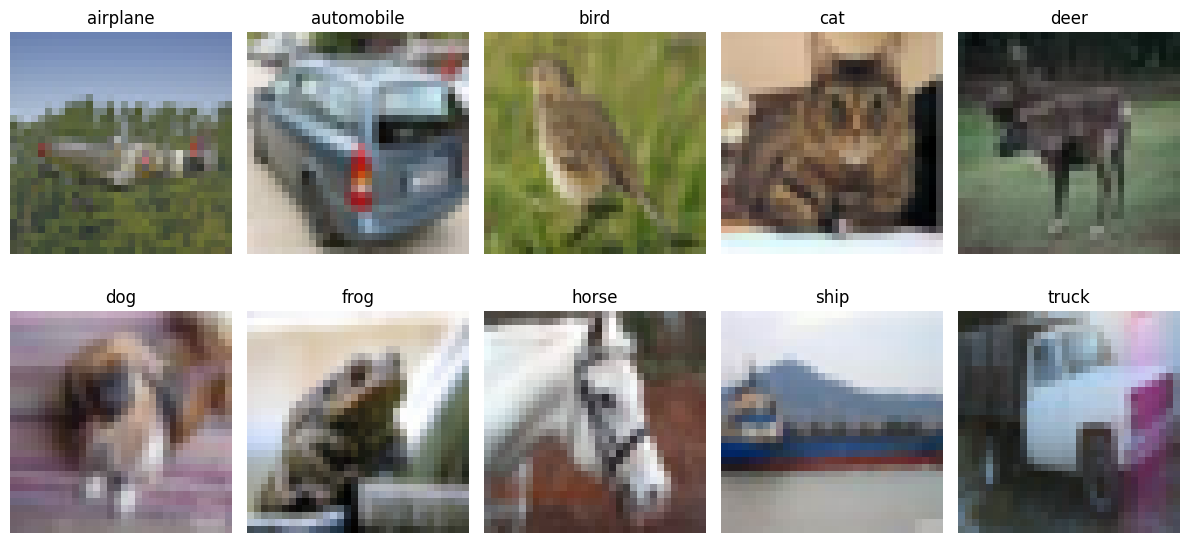

In [44]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 6))

for i, class_name in enumerate(class_names):

    image_path = train_df[train_df["class_name"] == class_name]["image_path"].iloc[0]

    image = Image.open(image_path)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [45]:
import random
from PIL import Image

# Select 10 random images
sample_images = random.sample(train_df["image_path"].tolist(), 10)

# Check image sizes
for i, image_path in enumerate(sample_images):
    image = Image.open(image_path)
    print(f"Image {i+1}: {image.size}")

Image 1: (32, 32)
Image 2: (32, 32)
Image 3: (32, 32)
Image 4: (32, 32)
Image 5: (32, 32)
Image 6: (32, 32)
Image 7: (32, 32)
Image 8: (32, 32)
Image 9: (32, 32)
Image 10: (32, 32)


In [46]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [47]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    horizontal_flip=True,
    zoom_range=0.1
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [48]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="class_name",
    target_size=(64, 64),
    batch_size=64,
    class_mode="categorical"
)

Found 4000 validated image filenames belonging to 10 classes.


In [49]:
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="class_name",
    target_size=(64, 64),
    batch_size=64,
    class_mode="categorical",
    shuffle=False
)

Found 1000 validated image filenames belonging to 10 classes.


In [54]:
from tensorflow.keras import layers, models

def residual_block(x, filters, stride=1):

    shortcut = x

    x = layers.Conv2D(filters, 3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, strides=stride, padding="same"
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_resnet18():

    inputs = layers.Input(shape=(64, 64, 3))

    x = layers.Conv2D(64, 7, strides=2, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    # ResNet18 has 8 residual blocks
    for filters, stride in [(64, 1), (64, 1),
                            (128, 2), (128, 1),
                            (256, 2), (256, 1),
                            (512, 2), (512, 1)]:
        x = residual_block(x, filters, stride)

    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    return model

In [55]:
model = build_resnet18()

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 32, 32,    │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_40[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_34 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ re_lu_34[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 16, 16,    │     36,928 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_41[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_35 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 16, 16,    │     36,928 │ re_lu_35[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_42[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_36 (ReLU)     │ (None, 16, 16,    │          0 │ add_16[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 16, 16,    │     36,928 │ re_lu_36[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_43[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_37 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 16, 16,    │     36,928 │ re_lu_37[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_44[0][0] 

 Total params: 11,196,042 (42.71 MB)

 Trainable params: 11,186,442 (42.67 MB)

 Non-trainable params: 9,600 (37.50 KB)

In [56]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
import time

start_time = time.time()

history = model.fit(
    train_generator,
    epochs=10,
    validation_data=test_generator,
    callbacks=[early_stop]
)

training_time = time.time() - start_time

print("Training time:", training_time)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 458s 7s/step - accuracy: 0.3467 - loss: 1.8765 - val_accuracy: 0.1710 - val_loss: 3.3370
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 416s 7s/step - accuracy: 0.4437 - loss: 1.5348 - val_accuracy: 0.1920 - val_loss: 3.0282
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 415s 7s/step - accuracy: 0.5222 - loss: 1.3433 - val_accuracy: 0.1580 - val_loss: 3.6383
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 417s 7s/step - accuracy: 0.5500 - loss: 1.2573 - val_accuracy: 0.3150 - val_loss: 2.1737
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 415s 7s/step - accuracy: 0.5930 - loss: 1.1517 - val_accuracy: 0.4500 - val_loss: 1.5719
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 411s 7s/step - accuracy: 0.6365 - loss: 1.0126 - val_accuracy: 0.3820 - val_loss: 2.1981
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 407s 6s/step - accuracy: 0.6417 - loss: 0.9955 - val_accuracy: 0.2990 - val_loss: 2.4926
Epoch 8/10
36/63 ━━━━━━━━━━━━━━━━━━━━ 2:47 6s/step - accuracy: 0.6960 - loss: 0.8652

In [ ]:
import numpy as np

test_generator.reset()

y_pred = model.predict(test_generator)

y_pred = np.argmax(y_pred, axis=1)

y_true = test_generator.classes

In [63]:
from sklearn.metrics import classification_report

class_names = list(test_generator.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

    airplane       0.49      0.40      0.44       100
  automobile       0.74      0.26      0.39       100
        bird       0.32      0.63      0.43       100
         cat       0.35      0.27      0.31       100
        deer       0.40      0.55      0.47       100
         dog       0.36      0.57      0.44       100
        frog       0.63      0.22      0.33       100
       horse       0.65      0.51      0.57       100
        ship       0.49      0.65      0.56       100
       truck       0.63      0.44      0.52       100

    accuracy                           0.45      1000
   macro avg       0.51      0.45      0.44      1000
weighted avg       0.51      0.45      0.44      1000



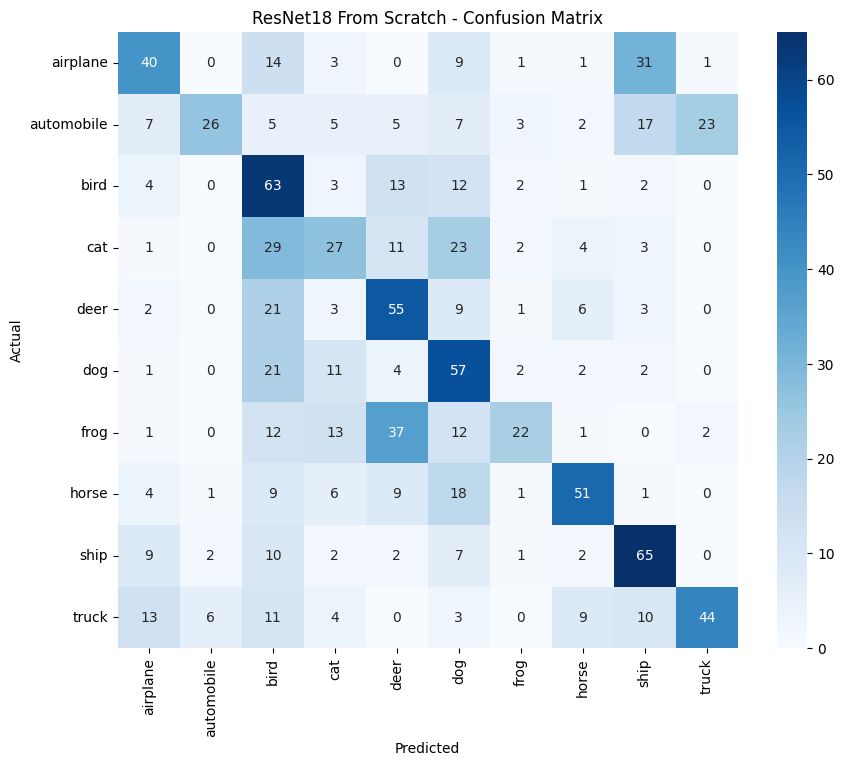

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet18 From Scratch - Confusion Matrix")
plt.show()

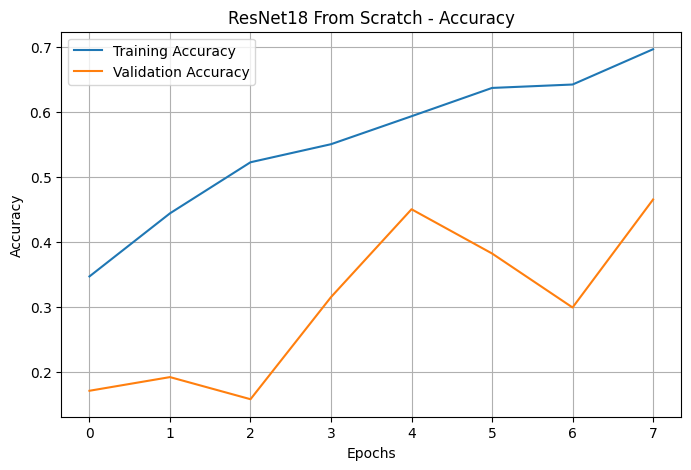

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ResNet18 From Scratch - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

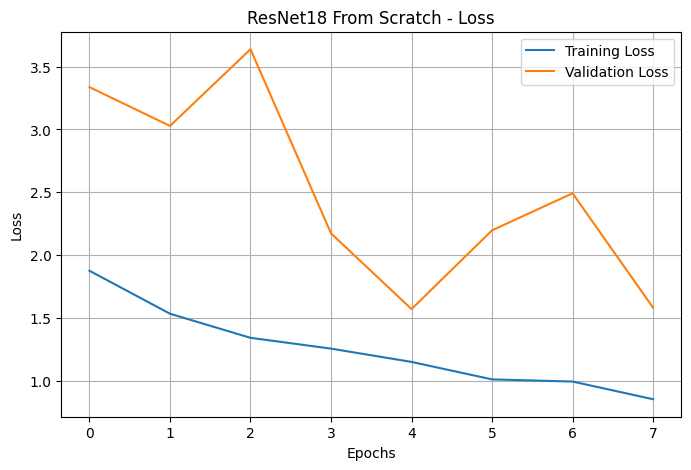

In [66]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ResNet18 From Scratch - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()